In [1]:
!pip install scikit-learn pandas numpy matplotlib seaborn joblib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 113.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 154.9 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 134.6 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4


In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score,
                             recall_score, f1_score, matthews_corrcoef,
                             confusion_matrix, classification_report)

In [4]:
df = pd.read_excel("/home/s2026aj05242/Desktop/ML_Assignment2/Dry_Bean_Dataset.xlsx")

print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (13611, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  object 
dtypes: float64(1

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.284549,29324.095717,20420.000000,36328.000000,44652.000000,61332.000000,254616.000000
Perimeter,13611.0,855.283459,214.289696,524.736000,703.523500,794.941000,977.213000,1985.370000
MajorAxisLength,13611.0,320.141867,85.694186,183.601165,253.303633,296.883367,376.495012,738.860153
MinorAxisLength,13611.0,202.270714,44.970091,122.512653,175.848170,192.431733,217.031741,460.198497
AspectRation,13611.0,1.583242,0.246678,1.024868,1.432307,1.551124,1.707109,2.430306
Eccentricity,13611.0,0.750895,0.092002,0.218951,0.715928,0.764441,0.810466,0.911423
ConvexArea,13611.0,53768.200206,29774.915817,20684.000000,36714.500000,45178.000000,62294.000000,263261.000000
EquivDiameter,13611.0,253.064220,59.177120,161.243764,215.068003,238.438026,279.446467,569.374358
Extent,13611.0,0.749733,0.049086,0.555315,0.718634,0.759859,0.786851,0.866195
Solidity,13611.0,0.987143,0.004660,0.919246,0.985670,0.988283,0.990013,0.994677


Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64


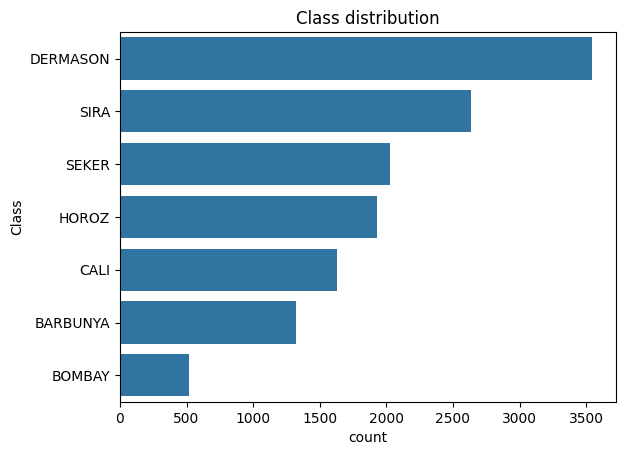

In [7]:
print(df["Class"].value_counts())
sns.countplot(y="Class", data=df, order=df["Class"].value_counts().index)
plt.title("Class distribution")
plt.show()

In [9]:
print("Missing values per column:")
print(df.isnull().sum())

Missing values per column:
Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRation       0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
Class              0
dtype: int64


In [10]:
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

Duplicate rows: 68
Shape after removing duplicates: (13543, 17)


In [11]:
df["Class"] = df["Class"].astype(str).str.strip()
feature_cols = [c for c in df.columns if c != "Class"]
df[feature_cols] = df[feature_cols].apply(pd.to_numeric, errors="coerce")

# drop any row that became NaN after conversion (normally none)
df = df.dropna().reset_index(drop=True)
print("Final shape:", df.shape)
print("Number of features:", len(feature_cols))

Final shape: (13543, 17)
Number of features: 16


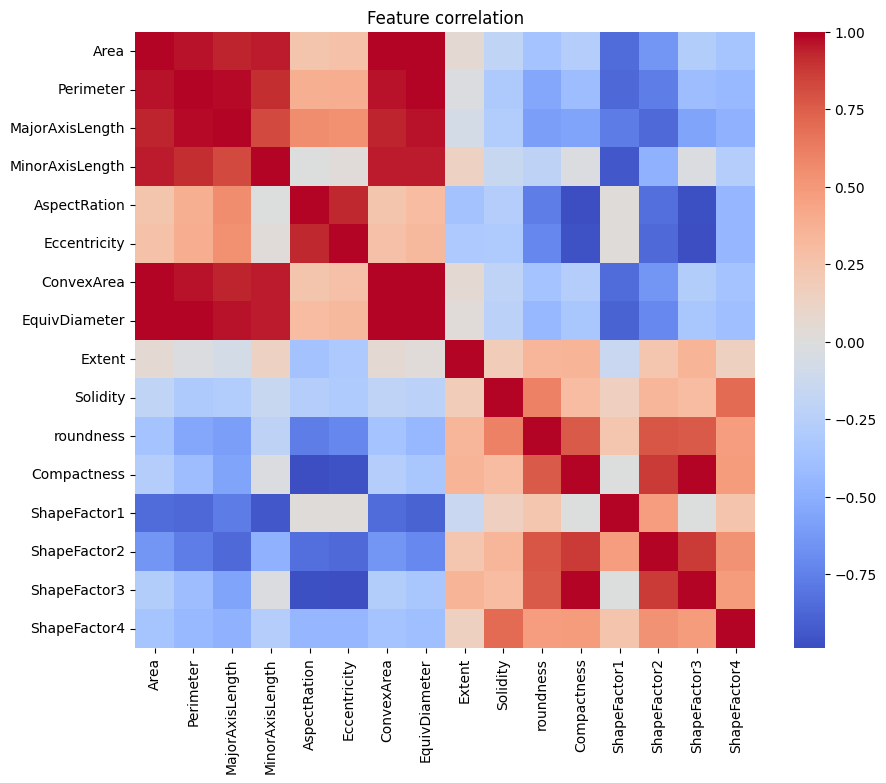

In [12]:
plt.figure(figsize=(10, 8))
sns.heatmap(df[feature_cols].corr(), cmap="coolwarm", center=0)
plt.title("Feature correlation")
plt.show()

In [13]:
X = df[feature_cols]
le = LabelEncoder()
y = le.fit_transform(df["Class"])

for i, name in enumerate(le.classes_):
    print(i, "->", name)

0 -> BARBUNYA
1 -> BOMBAY
2 -> CALI
3 -> DERMASON
4 -> HOROZ
5 -> SEKER
6 -> SIRA


In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print("Train:", X_train_s.shape, " Test:", X_test_s.shape)

Train: (10834, 16)  Test: (2709, 16)


In [15]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree":       DecisionTreeClassifier(random_state=42),
    "KNN":                 KNeighborsClassifier(n_neighbors=5),
    "Naive Bayes":         GaussianNB(),
    "SVM":                 SVC(kernel="rbf", probability=True, random_state=42)
}

In [16]:
def evaluate(model, X_te, y_te):
    y_pred = model.predict(X_te)
    y_prob = model.predict_proba(X_te)
    return {
        "Accuracy":  accuracy_score(y_te, y_pred),
        "AUC":       roc_auc_score(y_te, y_prob, multi_class="ovr", average="weighted"),
        "Precision": precision_score(y_te, y_pred, average="weighted"),
        "Recall":    recall_score(y_te, y_pred, average="weighted"),
        "F1":        f1_score(y_te, y_pred, average="weighted"),
        "MCC":       matthews_corrcoef(y_te, y_pred),
    }, y_pred

results = {}
predictions = {}

for name, model in models.items():
    print("Training", name, "...")
    model.fit(X_train_s, y_train)
    scores, y_pred = evaluate(model, X_test_s, y_test)
    results[name] = scores
    predictions[name] = y_pred
    print("  done. Accuracy =", round(scores["Accuracy"], 4))

Training Logistic Regression ...
  done. Accuracy = 0.9192
Training Decision Tree ...
  done. Accuracy = 0.8966
Training KNN ...
  done. Accuracy = 0.9155
Training Naive Bayes ...
  done. Accuracy = 0.897
Training SVM ...


/home/s2026aj05242/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


  done. Accuracy = 0.921


In [17]:
results_df = pd.DataFrame(results).T.round(4)
results_df.index.name = "ML Model Name"
results_df

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.9192,0.9934,0.9197,0.9192,0.9193,0.9023
Decision Tree,0.8966,0.9363,0.8965,0.8966,0.8964,0.8750
KNN,0.9155,0.9811,0.9163,0.9155,0.9157,0.8978
Naive Bayes,0.8970,0.9899,0.8997,0.8970,0.8972,0.8762
SVM,0.9210,0.9933,0.9214,0.9210,0.9211,0.9045


Best by Accuracy: SVM
Best by MCC     : SVM


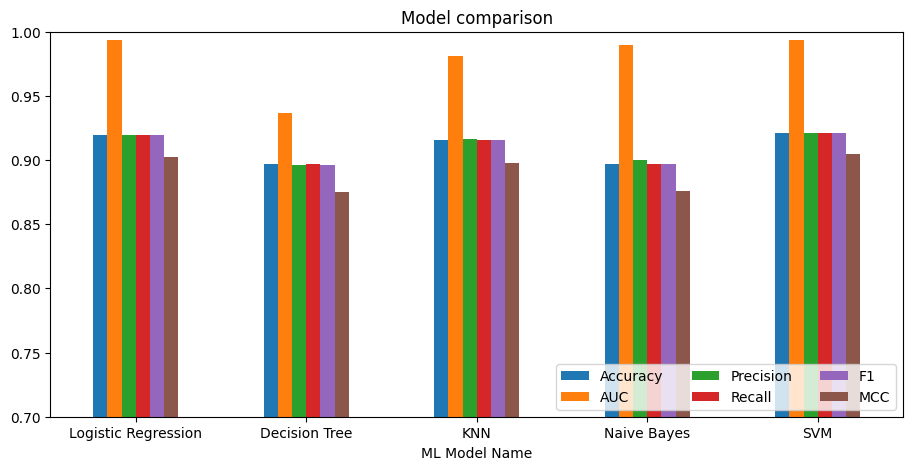

In [18]:
print("Best by Accuracy:", results_df["Accuracy"].idxmax())
print("Best by MCC     :", results_df["MCC"].idxmax())
results_df.plot(kind="bar", figsize=(11, 5), ylim=(0.7, 1.0))
plt.title("Model comparison")
plt.xticks(rotation=0)
plt.legend(loc="lower right", ncol=3)
plt.show()

Logistic Regression
              precision    recall  f1-score   support

    BARBUNYA       0.93      0.89      0.91       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.91      0.94      0.93       326
    DERMASON       0.93      0.91      0.92       709
       HOROZ       0.96      0.94      0.95       372
       SEKER       0.93      0.94      0.94       406
        SIRA       0.86      0.88      0.87       527

    accuracy                           0.92      2709
   macro avg       0.93      0.93      0.93      2709
weighted avg       0.92      0.92      0.92      2709



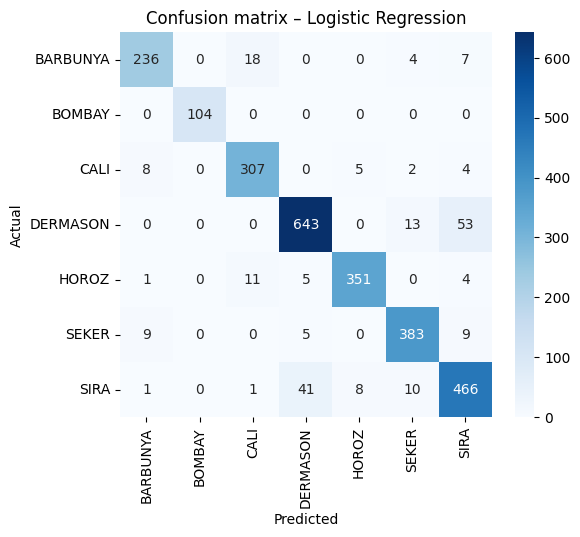

Decision Tree
              precision    recall  f1-score   support

    BARBUNYA       0.88      0.90      0.89       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.91      0.91      0.91       326
    DERMASON       0.89      0.91      0.90       709
       HOROZ       0.95      0.92      0.94       372
       SEKER       0.91      0.94      0.92       406
        SIRA       0.84      0.81      0.82       527

    accuracy                           0.90      2709
   macro avg       0.91      0.91      0.91      2709
weighted avg       0.90      0.90      0.90      2709



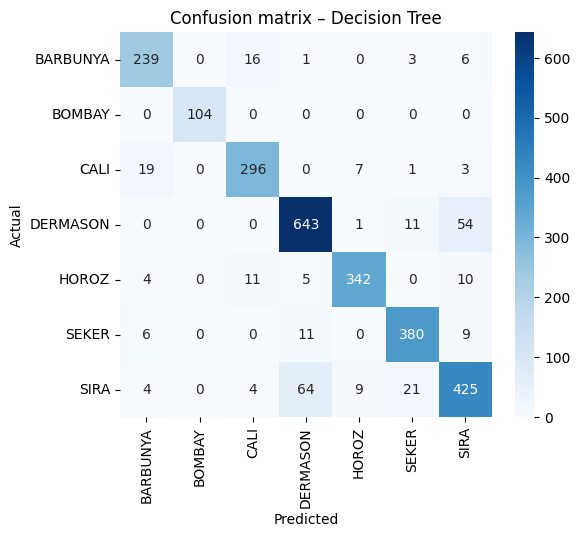

KNN
              precision    recall  f1-score   support

    BARBUNYA       0.93      0.88      0.90       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.90      0.95      0.92       326
    DERMASON       0.92      0.91      0.91       709
       HOROZ       0.96      0.93      0.95       372
       SEKER       0.95      0.94      0.94       406
        SIRA       0.85      0.87      0.86       527

    accuracy                           0.92      2709
   macro avg       0.93      0.93      0.93      2709
weighted avg       0.92      0.92      0.92      2709



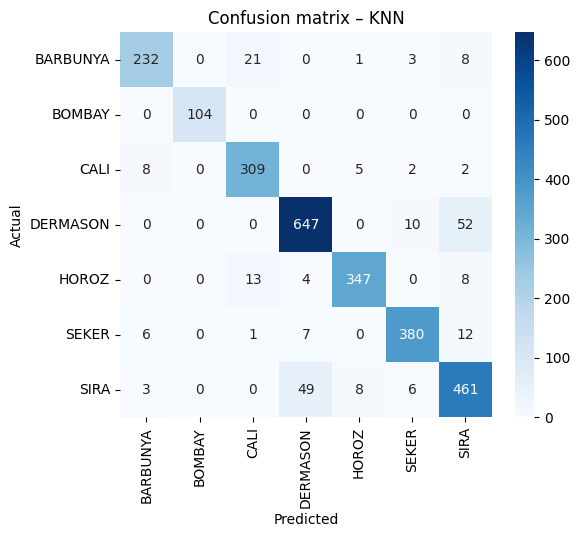

Naive Bayes
              precision    recall  f1-score   support

    BARBUNYA       0.87      0.80      0.83       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.86      0.92      0.89       326
    DERMASON       0.94      0.86      0.90       709
       HOROZ       0.95      0.95      0.95       372
       SEKER       0.92      0.94      0.93       406
        SIRA       0.81      0.90      0.85       527

    accuracy                           0.90      2709
   macro avg       0.91      0.91      0.91      2709
weighted avg       0.90      0.90      0.90      2709



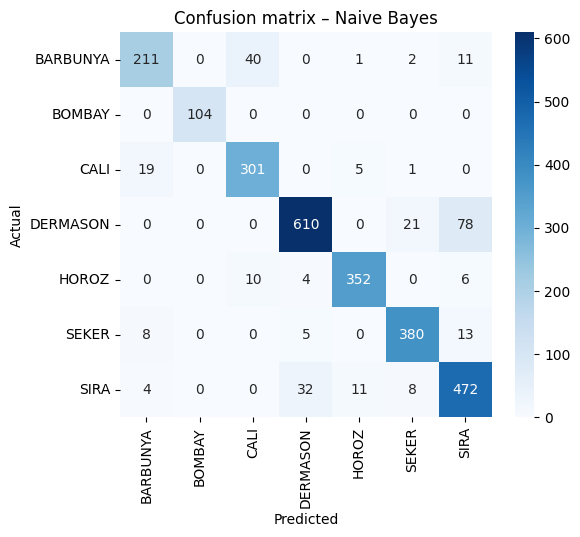

SVM
              precision    recall  f1-score   support

    BARBUNYA       0.94      0.89      0.91       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.92      0.95      0.93       326
    DERMASON       0.92      0.91      0.92       709
       HOROZ       0.96      0.94      0.95       372
       SEKER       0.93      0.95      0.94       406
        SIRA       0.86      0.88      0.87       527

    accuracy                           0.92      2709
   macro avg       0.93      0.93      0.93      2709
weighted avg       0.92      0.92      0.92      2709



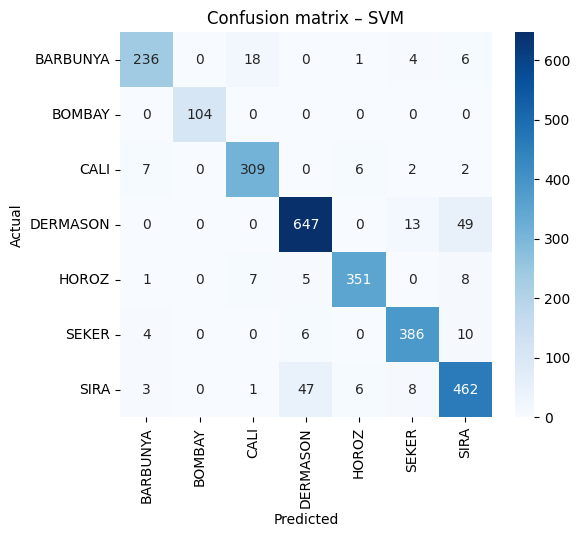

In [19]:
for name in models:
    print("=" * 60)
    print(name)
    print(classification_report(y_test, predictions[name], target_names=le.classes_))

    cm = confusion_matrix(y_test, predictions[name])
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=le.classes_, yticklabels=le.classes_)
    plt.title("Confusion matrix – " + name)
    plt.xlabel("Predicted"); plt.ylabel("Actual")
    plt.show()

In [20]:
os.makedirs("model", exist_ok=True)

file_names = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree":       "decision_tree.joblib",
    "KNN":                 "knn.joblib",
    "Naive Bayes":         "naive_bayes.joblib",
    "SVM":                 "svm.joblib",
}
for name, model in models.items():
    joblib.dump(model, os.path.join("model", file_names[name]))

joblib.dump(scaler, "model/scaler.joblib")
joblib.dump(le, "model/label_encoder.joblib")
joblib.dump(feature_cols, "model/feature_cols.joblib")

# test data (original, unscaled values + class name as target)
test_df = X_test.copy()
test_df["Class"] = le.inverse_transform(y_test)
test_df.to_csv("test_data.csv", index=False)

results_df.to_csv("model_results.csv")
print("Saved files:", os.listdir("model"))
print("test_data.csv shape:", test_df.shape)

Saved files: ['logistic_regression.joblib', 'decision_tree.joblib', 'knn.joblib', 'naive_bayes.joblib', 'svm.joblib', 'scaler.joblib', 'label_encoder.joblib', 'feature_cols.joblib']
test_data.csv shape: (2709, 17)
